# 02 — Benchmark del Modelo de Clasificación de Anomalías (`normal` / `caida` / `subida`)

Evaluamos **6 enfoques de detección/clasificación** sobre un conjunto de evaluación **completamente disjunto en restaurantes** (60 % train / 40 % eval), inyectando anomalías realistas de los 4 arquetipos del reto (`drop_1d`, `spike_1d`, `streak_2_4d`, `pure_ticket`), incluyendo `HybridMetaClassifier` con umbral desacoplado `[0, 1]` y `EnsembleCQRClassifier` contextual (`CQR + Peer + CrossChannel + Persistencia`).


In [5]:
import json, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "databricks" / "src" / "config.py").is_file())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from databricks.src.config import get_outputs_dir
from databricks.src.backtest import (
    archetype_recall_breakdown,
    build_neutral_keys,
    create_synthetic_benchmark,
    jury_metrics,
    split_train_eval_restaurants,
)
from databricks.src.classifiers import (
    CQRQuantileClassifier,
    EnsembleCQRClassifier,
    HybridMetaClassifier,
    IsolationForestClassifier,
    RobustZClassifier,
    SimpleSameDOWClassifier,
)

plt.rcParams["figure.dpi"] = 120
out_dir = get_outputs_dir()
df_feat = pd.read_parquet(out_dir / "silver_features.parquet")
print(f"Cargado silver_features.parquet: {len(df_feat):,} filas | Elegibles: {int(df_feat['is_eligible_for_alert'].sum()):,}")

df_tr_raw, df_ev_raw = split_train_eval_restaurants(df_feat, train_frac=0.60, seed=42)
train_bench = create_synthetic_benchmark(df_tr_raw, n_events=800, seed=101)
eval_bench = create_synthetic_benchmark(df_ev_raw, n_events=600, seed=2026)

print(f"Train cohort: {len(train_bench['df']):,} filas | {len(train_bench['gt_df'])} días anómalos inyectados")
print(f"Eval cohort : {len(eval_bench['df']):,} filas | {len(eval_bench['gt_df'])} días anómalos inyectados | "
      f"filas wild neutrales={eval_bench['wild_neutral_count']}")


Cargado silver_features.parquet: 1,377,194 filas | Elegibles: 1,081,923
Train cohort: 821,576 filas | 1106 días anómalos inyectados
Eval cohort : 555,618 filas | 885 días anómalos inyectados | filas wild neutrales=2025


In [6]:
# Entrenamiento/calibración de los 6 modelos en Train y evaluación estricta Out-of-Sample en Eval
models = [
    SimpleSameDOWClassifier(pct_threshold=0.45),
    RobustZClassifier(),
    CQRQuantileClassifier(),
    IsolationForestClassifier(),
    HybridMetaClassifier(),
    EnsembleCQRClassifier(),
]

rows_cmp = []
preds_eval = {}
preds_full = {}
arch_tables = []
neutral_keys = build_neutral_keys(eval_bench["eval_mask"], eval_bench["df"])

for clf in models:
    t0 = time.perf_counter()
    clf.fit(
        train_bench["df"],
        y_train=train_bench["y_class"],
        gt_train=train_bench["gt_df"],
        eval_mask_train=train_bench["eval_mask"],
    )
    p_eval = clf.predict_alerts(eval_bench["df"])
    m = jury_metrics(eval_bench["gt_df"], p_eval, neutral_keys=neutral_keys)
    p_full = clf.predict_alerts(df_feat)
    preds_eval[clf.name] = p_eval
    preds_full[clf.name] = p_full

    ab = archetype_recall_breakdown(eval_bench["gt_df"], p_eval)
    ab["model"] = clf.name
    arch_tables.append(ab)

    rows_cmp.append({
        "Modelo": clf.name,
        "Umbral": round(float(clf.threshold), 4),
        "F1 (Tipo)": m["f1"],
        "Precision": m["precision"],
        "Recall": m["recall"],
        "Precision@100": m["precision_at_100"],
        "Recall Impacto EUR": m["recall_impact_eur"],
        "F1 Detección": m["f1_detection"],
        "TP / FP / FN": f"{m['tp_exact']} / {m['fp']} / {m['fn']}",
        "Alertas Reales (Full)": int(len(p_full)),
        "Tiempo (s)": round(time.perf_counter() - t0, 2),
    })

cmp_df = pd.DataFrame(rows_cmp).sort_values(
    ["F1 (Tipo)", "Precision@100", "Recall Impacto EUR"], ascending=[False, False, False]
).reset_index(drop=True)
display(cmp_df)

arch_df = pd.concat(arch_tables, ignore_index=True).pivot(index="model", columns="archetype", values="recall")
print("\nRecall exacto por arquetipo de anomalía:")
display(arch_df)


,Modelo,Umbral,F1 (Tipo),Precision,Recall,Precision@100,Recall Impacto EUR,F1 Detección,TP / FP / FN,Alertas Reales (Full),Tiempo (s)
0,5. Ensemble CQR + Peer + CrossCh,4.0433,0.8721,0.9568,0.8011,1.0,0.8649,0.8721,709 / 32 / 176,3367,0.58
1,1. RobustZ + Peer + CrossCh,5.1476,0.8681,0.9829,0.7774,1.0,0.8252,0.8681,688 / 12 / 197,3742,1.55
2,2. LightGBM CQR (Quantiles),2.8643,0.8664,0.9679,0.7842,1.0,0.8581,0.8664,694 / 23 / 191,3359,0.35
3,3. IsolationForest Multiv.,0.1381,0.8137,0.8691,0.7650,1.0,0.8356,0.8137,677 / 102 / 208,3388,33.95
4,4. HybridMetaClassifier (LGBM),0.7316,0.7367,0.7144,0.7605,1.0,0.7834,0.7367,673 / 269 / 212,2386,52.18
5,0. SimpleSameDOW (Ref RBE),0.4500,0.0239,0.0121,0.8678,0.0,0.9632,0.0239,768 / 62698 / 117,159108,4.28



Recall exacto por arquetipo de anomalía:


archetype,drop_1d,pure_ticket,spike_1d,streak_2_4d
model,,,,
0. SimpleSameDOW (Ref RBE),0.9609,0.0122,0.9724,0.9463
1. RobustZ + Peer + CrossCh,0.8391,0.8902,0.6414,0.7687
2. LightGBM CQR (Quantiles),0.8391,0.9024,0.6897,0.7640
3. IsolationForest Multiv.,0.7565,0.9756,0.7034,0.7500
4. HybridMetaClassifier (LGBM),0.6913,0.8780,0.6897,0.7991
5. Ensemble CQR + Peer + CrossCh,0.8348,0.8780,0.6690,0.8131


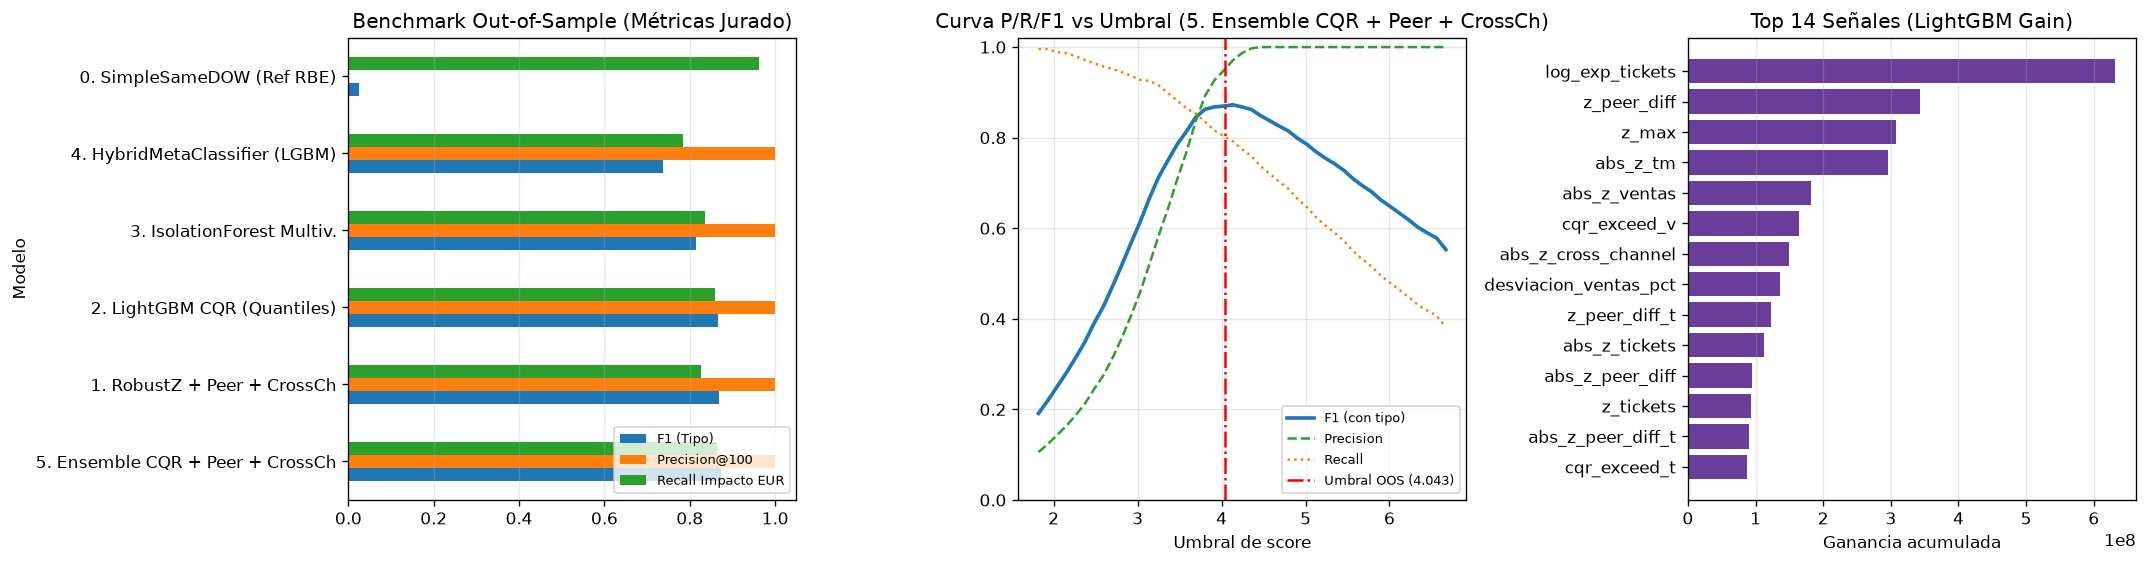

Matriz de confusión 3x3 — 5. Ensemble CQR + Peer + CrossCh (Out-of-Sample Eval):


,Pred: normal,Pred: caida,Pred: subida
Real: normal,552676,8,24
Real: caida,74,453,0
Real: subida,102,0,256


In [7]:
# Gráficos: comparativa de métricas oficiales, matriz de confusión 3x3 y curva de umbral + importancia
best_name = cmp_df.iloc[0]["Modelo"]
champion = next(m for m in models if m.name == best_name)
hybrid = next(m for m in models if "HybridMetaClassifier" in m.name)
scores_ev, tipos_ev, elig_ev = champion.predict_scores_and_tipos(eval_bench["df"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

plot_m = cmp_df.set_index("Modelo")[["F1 (Tipo)", "Precision@100", "Recall Impacto EUR"]]
plot_m.plot(kind="barh", ax=axes[0])
axes[0].set_title("Benchmark Out-of-Sample (Métricas Jurado)")
axes[0].set_xlim(0, 1.05)
axes[0].grid(axis="x", alpha=0.3)
axes[0].legend(loc="lower right", fontsize=8)

valid_ev = elig_ev & eval_bench["eval_mask"]
y_ev = eval_bench["y_class"]
is_tp_ev = ((y_ev == 1) & (tipos_ev == "caida")) | ((y_ev == 2) & (tipos_ev == "subida"))
n_gt_ev = int((y_ev[eval_bench["eval_mask"]] > 0).sum())
s_lo = max(0.15, float(champion.threshold) * 0.45)
s_hi = min(1.0, float(champion.threshold) * 1.65) if float(champion.threshold) <= 1.0 else float(champion.threshold) * 1.65
thrs = np.linspace(s_lo, s_hi, 45)
f1s, precs, recs = [], [], []
for th in thrs:
    mm = valid_ev & (scores_ev >= th)
    k = int(mm.sum())
    tp = int((is_tp_ev & mm).sum())
    pr = tp / k if k else 0.0
    rc = tp / n_gt_ev if n_gt_ev else 0.0
    f1s.append(2 * pr * rc / (pr + rc) if (pr + rc) else 0.0)
    precs.append(pr); recs.append(rc)

axes[1].plot(thrs, f1s, label="F1 (con tipo)", lw=2.2, color="#1f77b4")
axes[1].plot(thrs, precs, label="Precision", ls="--", color="#2ca02c")
axes[1].plot(thrs, recs, label="Recall", ls=":", color="#ff7f0e")
axes[1].axvline(champion.threshold, color="red", ls="-.", label=f"Umbral OOS ({champion.threshold:.3f})")
axes[1].set_title(f"Curva P/R/F1 vs Umbral ({champion.name})")
axes[1].set_xlabel("Umbral de score")
axes[1].set_ylim(0, 1.02)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

imp_df = hybrid.feature_importances().head(14).iloc[::-1]
axes[2].barh(imp_df["feature"], imp_df["importance_gain"], color="#6a3d9a")
axes[2].set_title("Top 14 Señales (LightGBM Gain)")
axes[2].set_xlabel("Ganancia acumulada")
axes[2].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

ev_mask = eval_bench["eval_mask"]
y_true = eval_bench["y_class"][ev_mask]
is_pred = (elig_ev & (scores_ev >= champion.threshold))[ev_mask]
t_pred = tipos_ev[ev_mask]
y_pred = np.where(~is_pred, 0, np.where(t_pred == "caida", 1, 2))
cm = pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=[0, 1, 2]),
    index=["Real: normal", "Real: caida", "Real: subida"],
    columns=["Pred: normal", "Pred: caida", "Pred: subida"],
)
print(f"Matriz de confusión 3x3 — {champion.name} (Out-of-Sample Eval):")
display(cm)


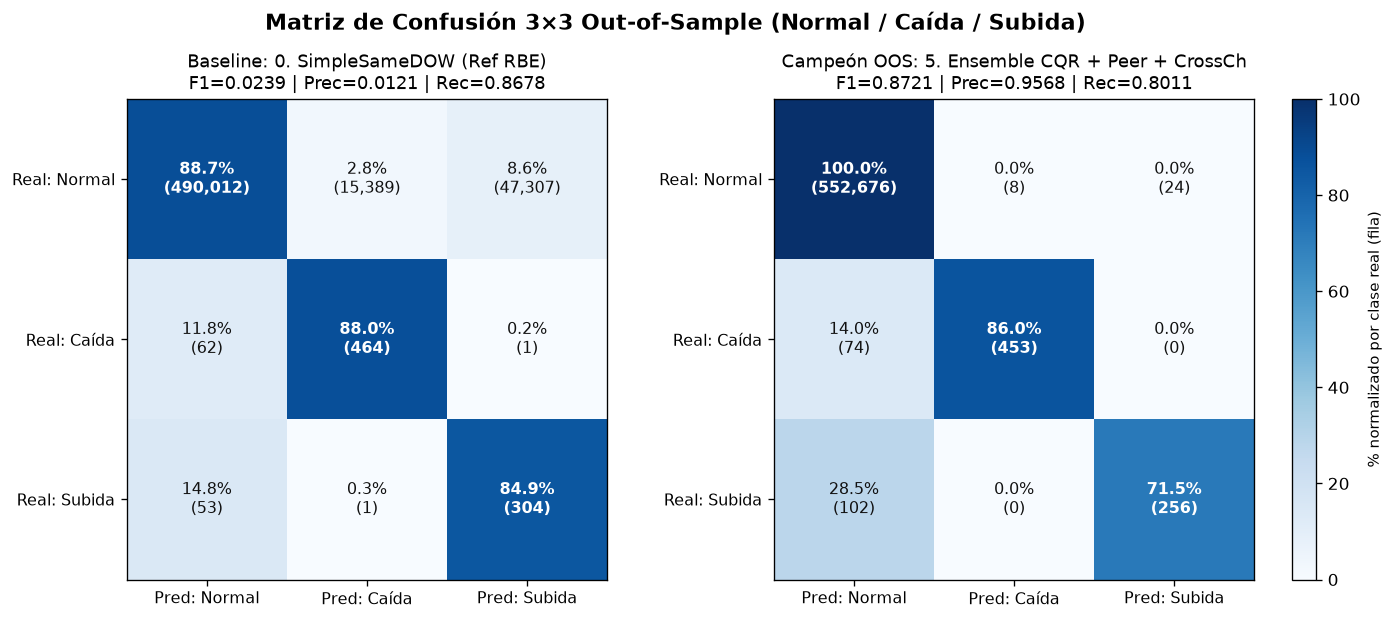

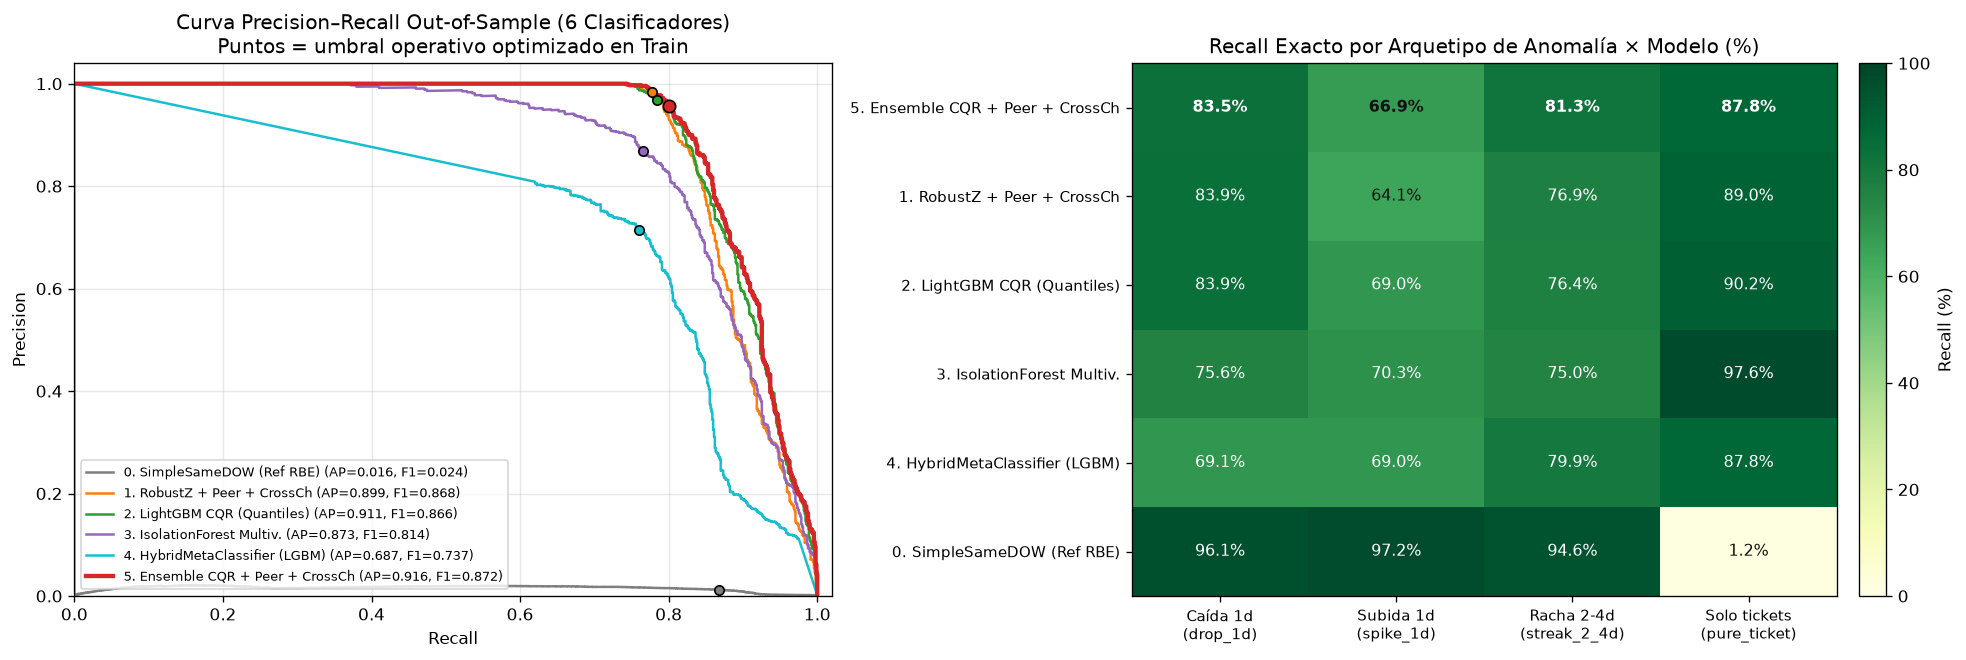

In [8]:
# Gráficos avanzados de evaluación: Matrices de Confusión 3x3 (Baseline vs Campeón), Curvas PR y Heatmap por Arquetipo
from sklearn.metrics import average_precision_score, precision_recall_curve

fig_dir = REPO_ROOT / "docs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

baseline_clf = next(m for m in models if "SimpleSameDOW" in m.name)
ev_mask = eval_bench["eval_mask"]
y_true_ev = eval_bench["y_class"][ev_mask]
class_labels = ["Normal", "Caída", "Subida"]


def _plot_cm_heatmap(ax, clf_obj, title_prefix):
    sc, tp, el = clf_obj.predict_scores_and_tipos(eval_bench["df"])
    pred_mask = (el & (sc >= clf_obj.threshold))[ev_mask]
    tp_ev = tp[ev_mask]
    y_pred = np.where(~pred_mask, 0, np.where(tp_ev == "caida", 1, 2))
    cm_raw = confusion_matrix(y_true_ev, y_pred, labels=[0, 1, 2])
    row_sums = np.maximum(cm_raw.sum(axis=1, keepdims=True), 1)
    cm_pct = 100.0 * cm_raw / row_sums

    im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
    ax.set_xticklabels([f"Pred: {c}" for c in class_labels], fontsize=9.5)
    ax.set_yticklabels([f"Real: {c}" for c in class_labels], fontsize=9.5)
    for i in range(3):
        for j in range(3):
            txt_col = "white" if cm_pct[i, j] >= 55 else "#111111"
            ax.text(
                j, i, f"{cm_pct[i, j]:.1f}%\n({cm_raw[i, j]:,})",
                ha="center", va="center", color=txt_col, fontsize=9.5,
                fontweight="bold" if i == j else "normal",
            )
    m_row = cmp_df.loc[cmp_df["Modelo"] == clf_obj.name].iloc[0]
    ax.set_title(
        f"{title_prefix}: {clf_obj.name}\n"
        f"F1={m_row['F1 (Tipo)']:.4f} | Prec={m_row['Precision']:.4f} | Rec={m_row['Recall']:.4f}",
        fontsize=10.5,
    )
    return im


# 1) Matrices de confusión 3x3 lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
_plot_cm_heatmap(axes[0], baseline_clf, "Baseline")
im_right = _plot_cm_heatmap(axes[1], champion, "Campeón OOS")
cbar = fig.colorbar(im_right, ax=axes.ravel().tolist(), fraction=0.025, pad=0.03)
cbar.set_label("% normalizado por clase real (fila)", fontsize=9)
fig.suptitle("Matriz de Confusión 3×3 Out-of-Sample (Normal / Caída / Subida)", fontsize=13, fontweight="bold", y=1.02)
plt.savefig(fig_dir / "02_confusion_matrices_comparativa.png", dpi=180, bbox_inches="tight")
plt.show()

# 2) Curvas Precision-Recall multi-modelo + Heatmap Recall por Arquetipo x Modelo
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.6))

y_bin_ev = (y_true_ev > 0).astype(int)
palette = ["#7f7f7f", "#ff7f0e", "#2ca02c", "#9467bd", "#17becf", "#d62728"]

for clf_obj, col in zip(models, palette):
    sc, tp, el = clf_obj.predict_scores_and_tipos(eval_bench["df"])
    # Filas no elegibles reciben score -inf para reflejar los guardrails reales
    sc_eff = np.where(el, sc, -1e9)[ev_mask]
    prec_c, rec_c, _ = precision_recall_curve(y_bin_ev, sc_eff)
    ap = average_precision_score(y_bin_ev, sc_eff)
    m_row = cmp_df.loc[cmp_df["Modelo"] == clf_obj.name].iloc[0]
    lw = 2.6 if clf_obj.name == champion.name else 1.5
    axes[0].plot(rec_c, prec_c, label=f"{clf_obj.name} (AP={ap:.3f}, F1={m_row['F1 (Tipo)']:.3f})", lw=lw, color=col)
    axes[0].scatter([m_row["Recall"]], [m_row["Precision"]], color=col, s=55 if clf_obj.name == champion.name else 32,
                    edgecolor="black", zorder=6)

axes[0].set_xlim(0, 1.02)
axes[0].set_ylim(0, 1.04)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Curva Precision–Recall Out-of-Sample (6 Clasificadores)\nPuntos = umbral operativo optimizado en Train")
axes[0].legend(loc="lower left", fontsize=8)
axes[0].grid(alpha=0.3)

# Heatmap Arquetipo x Modelo ordenado según ranking de cmp_df
arch_ordered = arch_df.reindex(cmp_df["Modelo"])
arch_label_map = {
    "drop_1d": "Caída 1d\n(drop_1d)",
    "spike_1d": "Subida 1d\n(spike_1d)",
    "streak_2_4d": "Racha 2-4d\n(streak_2_4d)",
    "pure_ticket": "Solo tickets\n(pure_ticket)",
}
arch_cols = [c for c in ["drop_1d", "spike_1d", "streak_2_4d", "pure_ticket"] if c in arch_ordered.columns]
arch_mat = arch_ordered[arch_cols].to_numpy(dtype=float) * 100.0
im_a = axes[1].imshow(arch_mat, cmap="YlGn", vmin=0, vmax=100, aspect="auto")
axes[1].set_xticks(range(len(arch_cols)))
axes[1].set_xticklabels([arch_label_map[c] for c in arch_cols], fontsize=9)
axes[1].set_yticks(range(len(arch_ordered)))
axes[1].set_yticklabels(arch_ordered.index, fontsize=8.8)
for i in range(arch_mat.shape[0]):
    for j in range(arch_mat.shape[1]):
        val = arch_mat[i, j]
        axes[1].text(j, i, f"{val:.1f}%", ha="center", va="center",
                     color="white" if val >= 68 else "#111111", fontsize=9.5,
                     fontweight="bold" if i == 0 else "normal")
axes[1].set_title("Recall Exacto por Arquetipo de Anomalía × Modelo (%)")
fig.colorbar(im_a, ax=axes[1], fraction=0.04, pad=0.03, label="Recall (%)")

plt.tight_layout()
plt.savefig(fig_dir / "02_pr_curves_y_arquetipos.png", dpi=180, bbox_inches="tight")
plt.show()


In [9]:
# Guardar predicciones del modelo campeón y métricas sintéticas para Notebook 03
champ_name = champion.name
champ_alerts = preds_full[champ_name].copy()
champ_metrics = jury_metrics(eval_bench["gt_df"], preds_eval[champ_name], neutral_keys=neutral_keys)

if "Ensemble" in champ_name:
    model_ver = "v3_ensemble_cqr_ctx"
elif "Hybrid" in champ_name:
    model_ver = "v2_hybrid_lgbm_cqr"
elif "CQR" in champ_name:
    model_ver = "v2_lgbm_cqr_quantiles"
else:
    model_ver = "v2_robust_z_ctx"

extra_params = {}
if isinstance(champion, EnsembleCQRClassifier):
    extra_params = {
        "alpha_peer": float(champion.alpha_peer),
        "alpha_cross_channel": float(champion.alpha_xc),
        "alpha_persistencia": float(champion.alpha_nbr),
    }

print(f"Modelo campeón seleccionado por F1 OOS: {champ_name} ({model_ver}) | Umbral={champion.threshold:.4f}")
print(f"Alertas reales emitidas en todo el dataset: {len(champ_alerts):,}")
print("Reparto por canal y tipo:")
display(champ_alerts.groupby(["canal", "tipo"]).size().unstack(fill_value=0))

champ_alerts.to_parquet(out_dir / "champion_alerts.parquet", index=False)
with open(out_dir / "champion_metrics.json", "w", encoding="utf-8") as f:
    json.dump({
        "model_version": model_ver,
        "champion_name": champ_name,
        "threshold": float(champion.threshold),
        "extra_params": extra_params,
        "metrics": champ_metrics,
    }, f, indent=2)


Modelo campeón seleccionado por F1 OOS: 5. Ensemble CQR + Peer + CrossCh (v3_ensemble_cqr_ctx) | Umbral=4.0433
Alertas reales emitidas en todo el dataset: 3,367
Reparto por canal y tipo:


tipo,caida,subida
canal,,
autoking,560,144
domicilio,837,202
sala,517,1107
